# Assignment 3 — Question 2
# Finite State Transducer (FST) for Noun Morphology

---



In [34]:
# Install required packages (run once)
# !pip install automathon PyPDF2

import string
import PyPDF2
import graphviz
from IPython.display import Image, display

print("Imports successful!")

Imports successful!


## 1. Extract Nouns from the Brown Corpus PDF

The file `brown_corpus.pdf` contains all nouns from the Brown corpus. We extract them and save to `brown_nouns.txt`.

In [35]:
# ============================================================
# Extract nouns from brown_corpus.pdf & save to file
# ============================================================

reader = PyPDF2.PdfReader("brown_corpus.pdf")
print(f"PDF loaded: {len(reader.pages)} pages")

# Extract all words from every page
all_words_raw = []
for page in reader.pages:
    text = page.extract_text()
    words = text.split()
    all_words_raw.extend(words)

print(f"Total words extracted (with duplicates): {len(all_words_raw)}")

# Clean: keep only alphabetic words, lowercase them, get unique sorted list
brown_nouns = sorted(set(
    w.lower() for w in all_words_raw if w.isalpha()
))

# Save to brown_nouns.txt
with open("brown_nouns.txt", "w", encoding="utf-8") as f:
    for noun in brown_nouns:
        f.write(noun + "\n")

print(f"Unique nouns (alphabetic, lowercased): {len(brown_nouns)}")
print(f"Saved to brown_nouns.txt")
print(f"\nFirst 15 nouns: {brown_nouns[:15]}")
print(f"Last 10 nouns:  {brown_nouns[-10:]}")

PDF loaded: 295 pages
Total words extracted (with duplicates): 205074
Unique nouns (alphabetic, lowercased): 17425
Saved to brown_nouns.txt

First 15 nouns: ['a', 'aaa', 'aba', 'abandon', 'abandonment', 'abaringe', 'abasement', 'abberations', 'abbey', 'abbot', 'abbreviation', 'abbreviations', 'abdomen', 'abdominis', 'abduction']
Last 10 nouns:  ['zipper', 'zlotys', 'zombie', 'zombies', 'zone', 'zones', 'zoning', 'zoo', 'zoologist', 'zoology']


## 2. FST Design

### Formal FST Definition




In [36]:
# ============================================================
# 3. FST Implementation
# ============================================================

class NounMorphFST:
    """
    Finite State Transducer for English noun morphological analysis.
    
    States:
        q0       - Start state
        q_read   - Reading characters (identity transduction)
        q_acc_sg - Accept as singular noun
        q_acc_pl - Accept as plural noun
        q_dead   - Dead/rejection state
    
    The FST uses a transition table with (input_symbol, output_symbol)
    pairs on each edge.
    """
    
    # Consonants used for Y-replacement validation
    CONSONANTS = set('bcdfghjklmnpqrstvwxyz')
    
    def __init__(self, lexicon):
        """
        Initialize the FST with a lexicon of valid noun roots.
        
        Parameters:
            lexicon: set of valid singular noun forms
        """
        self.lexicon = set(lexicon)
        
        # ---- State set ----
        self.states = {
            'q0',        # Start
            'q_read',    # Reading stem characters
            'q_acc_sg',  # Accepted as singular
            'q_acc_pl',  # Accepted as plural
            'q_dead',    # Rejection / invalid word
        }
        
        # ---- Input alphabet ----
        self.input_alphabet = set(string.ascii_lowercase)
        
        # ---- Output alphabet ----
        self.output_alphabet = set(string.ascii_lowercase) | {
            '+', 'N', 'S', 'G', 'P', 'L',   # for tags like +N+SG, +N+PL
            'epsilon',                         # epsilon (no output)
        }
        
        self.start_state = 'q0'
        self.accept_states = {'q_acc_sg', 'q_acc_pl'}
        
        # ---- Transition table ----
        self.transition_table = self._build_transition_table()
    
    def _build_transition_table(self):
        """
        Build the transition table.
        
        Returns a dict: (state, input_char) -> (next_state, output)
        """
        table = {}
        
        # q0 --[a-z / a-z]--> q_read  (identity transduction on first char)
        for ch in string.ascii_lowercase:
            table[('q0', ch)] = ('q_read', ch)
        
        # q_read --[a-z / a-z]--> q_read  (keep reading, identity output)
        for ch in string.ascii_lowercase:
            table[('q_read', ch)] = ('q_read', ch)
        
        # q_dead is a sink: all inputs loop back with no output
        for ch in string.ascii_lowercase:
            table[('q_dead', ch)] = ('q_dead', 'epsilon')
        
        return table
    
    def _requires_e_insertion(self, root):
        """Check if a root requires E-insertion for pluralization.
        
        Roots ending in -s, -z, -x, -ch, -sh require -es (not just -s).
        """
        return root.endswith(('s', 'z', 'x', 'ch', 'sh'))
    
    def _requires_y_replacement(self, root):
        """Check if a root requires Y-replacement for pluralization.
        
        Roots ending in consonant + y require -ies (not just -s).
        e.g., city -> cities, NOT citys
        """
        return (len(root) >= 2 and
                root.endswith('y') and
                root[-2] in self.CONSONANTS)
    
    def _strip_plural(self, word):
        """
        Apply morphological rules to recover a singular root.
        
        Rules applied in priority order:
        1. E-insertion: -shes/-ches/-ses/-zes/-xes -> strip -es
        2. Y-replacement: -ies -> -y
        3. S-addition: -s -> strip -s
           GUARD: root must NOT end in s/z/x/ch/sh (needs E-insertion)
                  or consonant+y (needs Y-replacement)
        
        Returns:
            (root, rule_applied) if valid plural found
            (None, None)        if no valid decomposition
        """
        candidates = []
        
        # --- Rule 1: E-insertion (highest priority, most specific) ---
        if word.endswith('shes') and len(word) > 4:
            candidates.append((word[:-2], 'E-insertion'))     # watches -> watch
        if word.endswith('ches') and len(word) > 4:
            candidates.append((word[:-2], 'E-insertion'))     # churches -> church
        if word.endswith('ses') and len(word) > 3:
            candidates.append((word[:-2], 'E-insertion'))     # buses -> bus
        if word.endswith('zes') and len(word) > 3:
            candidates.append((word[:-2], 'E-insertion'))     # buzzes -> buzz
        if word.endswith('xes') and len(word) > 3:
            candidates.append((word[:-2], 'E-insertion'))     # foxes -> fox
        
        # --- Rule 2: Y-replacement ---
        if word.endswith('ies') and len(word) > 3:
            candidates.append((word[:-3] + 'y', 'Y-replacement'))  # cities -> city
        
        # --- Rule 3: S-addition (most general, lowest priority) ---
        # GUARD: Only allow S-addition if the root does NOT require
        #        E-insertion or Y-replacement. This prevents invalid
        #        forms like 'foxs', 'citys', 'churchs' from being accepted.
        if word.endswith('s') and len(word) > 1 and not word.endswith('ss'):
            root_candidate = word[:-1]
            if (not self._requires_e_insertion(root_candidate) and
                not self._requires_y_replacement(root_candidate)):
                candidates.append((root_candidate, 'S-addition'))  # cats -> cat
        
        # Validate candidates against the lexicon
        for root, rule in candidates:
            if root in self.lexicon:
                return root, rule
        
        return None, None
    
    def transduce(self, word):
        """
        Run the FST on an input word.
        
        Phase 1: Character-level FST reads the word (q0 -> q_read)
        Phase 2: At end-of-input, morphological analysis determines
                 the final state (q_acc_sg, q_acc_pl, or q_dead)
        
        IMPORTANT: Plural rules are checked FIRST because the lexicon
        contains both singular and plural forms.
        
        Returns:
            str: The morphological analysis or 'Invalid Word'
        """
        # Phase 1: Validate input through character-level transitions
        state = 'q0'
        output_chars = []
        
        for ch in word:
            key = (state, ch)
            if key in self.transition_table:
                state, out = self.transition_table[key]
                if out != 'epsilon':
                    output_chars.append(out)
            else:
                state = 'q_dead'
                break
        
        # Empty string or dead state -> reject
        if state == 'q_dead' or state == 'q0':
            return "Invalid Word"
        
        consumed_word = ''.join(output_chars)
        
        # Phase 2: Morphological analysis at end of input
        # Step 1: Try to decompose as plural FIRST
        root, rule = self._strip_plural(consumed_word)
        if root is not None:
            state = 'q_acc_pl'
            return f"{root}+N+PL"
        
        # Step 2: If no plural rule matched, check if word is singular
        if consumed_word in self.lexicon:
            state = 'q_acc_sg'
            return f"{consumed_word}+N+SG"
        
        # No valid analysis
        state = 'q_dead'
        return "Invalid Word"
    
    def get_transition_table_display(self):
        """Return a readable summary of the transition table."""
        summary = []
        summary.append("=" * 80)
        summary.append("FST TRANSITION TABLE")
        summary.append("=" * 80)
        summary.append(f"{'Current State':<15} {'Input':<10} {'Next State':<15} {'Output':<10}")
        summary.append("-" * 60)
        summary.append(f"{'q0':<15} {'a-z':<10} {'q_read':<15} {'a-z (identity)'}")
        summary.append(f"{'q0':<15} {'non a-z':<10} {'q_dead':<15} {'epsilon'}")
        summary.append(f"{'q_read':<15} {'a-z':<10} {'q_read':<15} {'a-z (identity)'}")
        summary.append("-" * 60)
        summary.append("End-of-input transitions (plural checked FIRST):")
        summary.append(f"  {'...shes/ches':<15} -> strip -es  -> {'q_acc_pl':<12} root+N+PL  [E-insertion]")
        summary.append(f"  {'...ses/zes/xes':<15} -> strip -es  -> {'q_acc_pl':<12} root+N+PL  [E-insertion]")
        summary.append(f"  {'...ies':<15} -> -ies->-y   -> {'q_acc_pl':<12} root+N+PL  [Y-replacement]")
        summary.append(f"  {'...s':<15} -> strip -s   -> {'q_acc_pl':<12} root+N+PL  [S-addition]")
        summary.append(f"  {'  GUARD:':<15}    root must NOT end in s/z/x/ch/sh or consonant+y")
        summary.append(f"  {'(no rule)':<15} -> as-is      -> {'q_acc_sg':<12} word+N+SG  [Singular]")
        summary.append("-" * 60)
        summary.append(f"{'q_dead':<15} {'any':<10} {'q_dead':<15} {'epsilon (sink)'}")
        summary.append("=" * 80)
        return "\n".join(summary)


print("NounMorphFST class defined successfully!")

NounMorphFST class defined successfully!


In [37]:
# ============================================================
# 4. Build the lexicon and instantiate the FST
# ============================================================

with open("brown_nouns.txt", "r", encoding="utf-8") as f:
    all_nouns = [line.strip() for line in f if line.strip()]

lexicon = set(all_nouns)
fst = NounMorphFST(lexicon)

print(f"FST States:          {fst.states}")
print(f"Start State:         {fst.start_state}")
print(f"Accept States:       {fst.accept_states}")
print(f"Input Alphabet:      {{a, b, ..., z}} (26 symbols)")
print(f"Output Alphabet:     {{a-z, +, N, S, G, P, L, epsilon}} (33 symbols)")
print(f"Lexicon Size:        {len(fst.lexicon)}")
print(f"Transition Entries:  {len(fst.transition_table)}")
print()
print(fst.get_transition_table_display())

FST States:          {'q_acc_pl', 'q_read', 'q_dead', 'q_acc_sg', 'q0'}
Start State:         q0
Accept States:       {'q_acc_pl', 'q_acc_sg'}
Input Alphabet:      {a, b, ..., z} (26 symbols)
Output Alphabet:     {a-z, +, N, S, G, P, L, epsilon} (33 symbols)
Lexicon Size:        17425
Transition Entries:  78

FST TRANSITION TABLE
Current State   Input      Next State      Output    
------------------------------------------------------------
q0              a-z        q_read          a-z (identity)
q0              non a-z    q_dead          epsilon
q_read          a-z        q_read          a-z (identity)
------------------------------------------------------------
End-of-input transitions (plural checked FIRST):
  ...shes/ches    -> strip -es  -> q_acc_pl     root+N+PL  [E-insertion]
  ...ses/zes/xes  -> strip -es  -> q_acc_pl     root+N+PL  [E-insertion]
  ...ies          -> -ies->-y   -> q_acc_pl     root+N+PL  [Y-replacement]
  ...s            -> strip -s   -> q_acc_pl     root+N+P

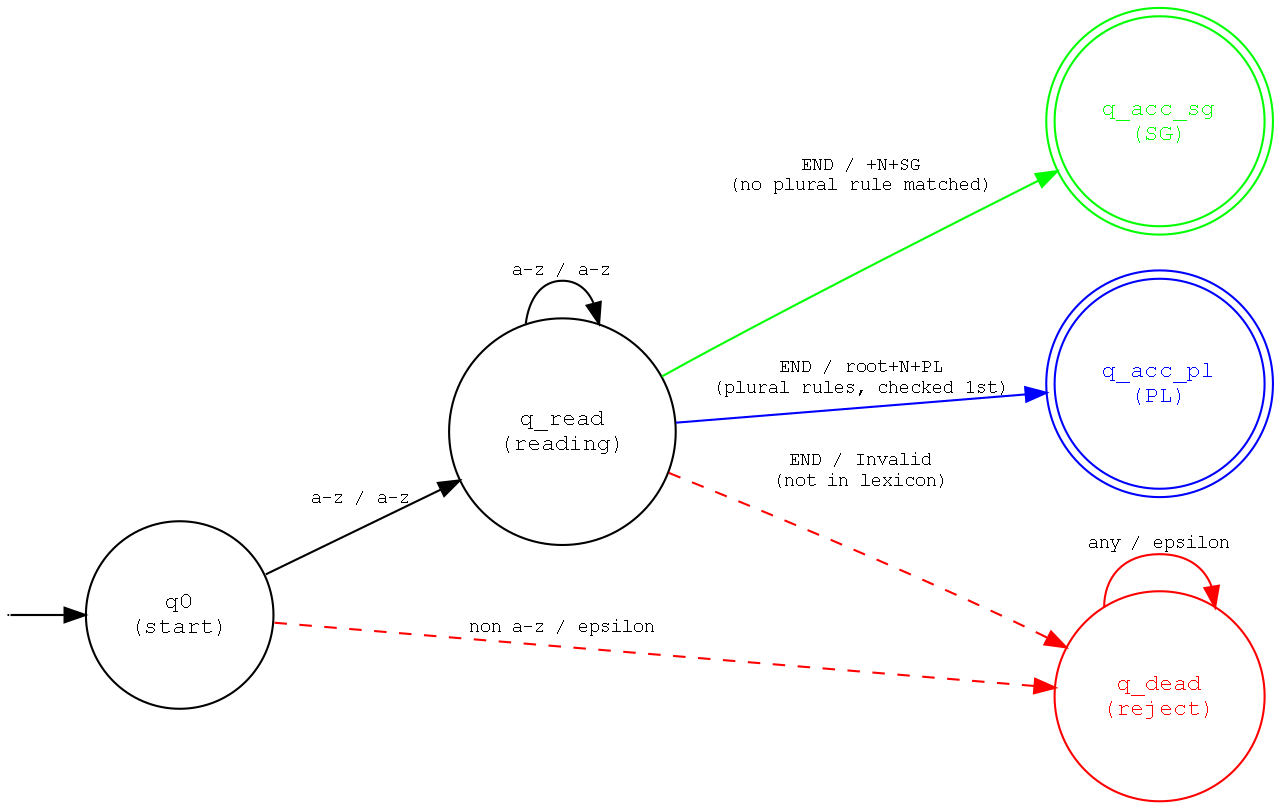


FST Diagram: Plural rules are checked FIRST at end-of-input.
S-addition has a guard that rejects roots needing E-insertion or Y-replacement.


In [38]:
# ============================================================
# 5. Visualize the FST
# ============================================================

def draw_fst():
    """Draw the main FST using graphviz."""
    dot = graphviz.Digraph('FST', format='png')
    dot.attr(rankdir='LR', size='12,6', dpi='150')
    dot.attr('node', shape='circle', fontsize='11', fontname='Courier')
    dot.attr('edge', fontsize='9', fontname='Courier')
    
    # Invisible start arrow
    dot.node('start', shape='point', width='0')
    
    # States
    dot.node('q0', 'q0\n(start)')
    dot.node('q_read', 'q_read\n(reading)')
    dot.node('q_acc_sg', 'q_acc_sg\n(SG)', shape='doublecircle', color='green', fontcolor='green')
    dot.node('q_acc_pl', 'q_acc_pl\n(PL)', shape='doublecircle', color='blue', fontcolor='blue')
    dot.node('q_dead', 'q_dead\n(reject)', shape='circle', color='red', fontcolor='red')
    
    # Edges
    dot.edge('start', 'q0')
    dot.edge('q0', 'q_read', label='a-z / a-z')
    dot.edge('q_read', 'q_read', label='a-z / a-z')
    dot.edge('q_read', 'q_acc_pl', label='END / root+N+PL\n(plural rules, checked 1st)', color='blue')
    dot.edge('q_read', 'q_acc_sg', label='END / +N+SG\n(no plural rule matched)', color='green')
    dot.edge('q_read', 'q_dead', label='END / Invalid\n(not in lexicon)', color='red', style='dashed')
    dot.edge('q_dead', 'q_dead', label='any / epsilon', color='red')
    dot.edge('q0', 'q_dead', label='non a-z / epsilon', color='red', style='dashed')
    
    dot.render('fst_noun_morph', cleanup=True)
    return 'fst_noun_morph.png'

fst_img = draw_fst()
display(Image(filename=fst_img))
print("\nFST Diagram: Plural rules are checked FIRST at end-of-input.")
print("S-addition has a guard that rejects roots needing E-insertion or Y-replacement.")

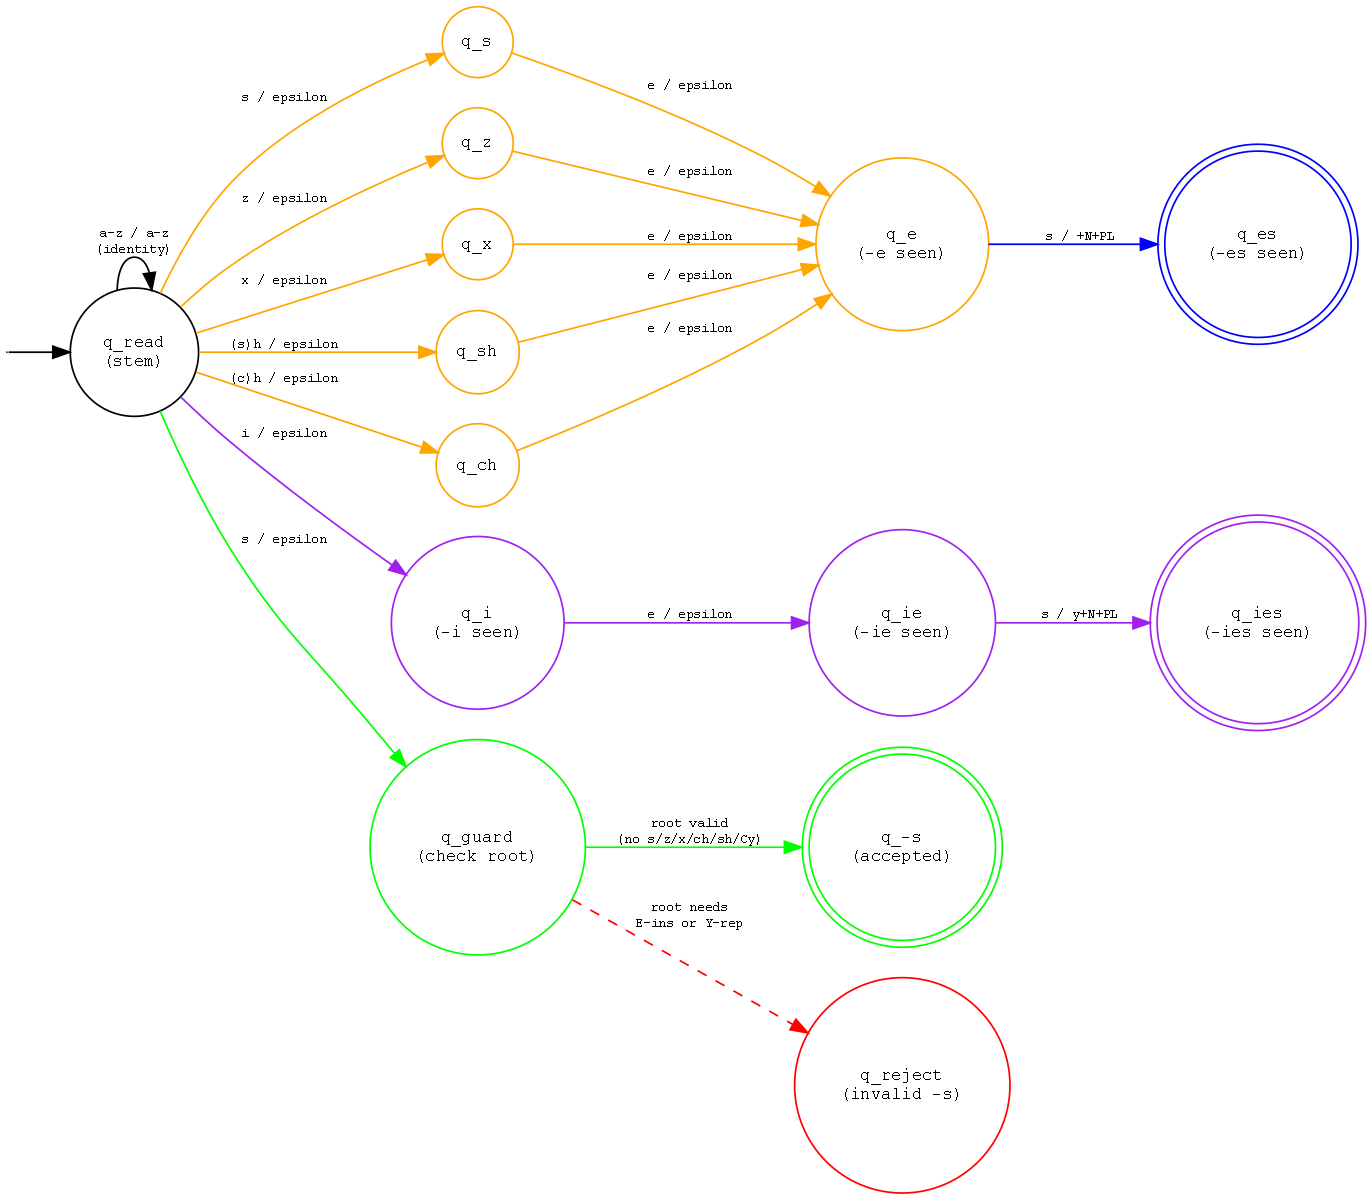


Plural Rules Sub-FST:
  Orange paths = E-insertion (stem ends in s/z/x/sh/ch, then -es)
  Purple path  = Y-replacement (-ies -> -y)
  Green path   = S-addition (simple -s, with guard)
  Guard rejects: foxs, citys, churchs, boxs, watchs (incorrect plurals)


In [39]:
# ============================================================
# 6. Visualize the Plural-Suffix Sub-FST (Detailed View)
# ============================================================

def draw_plural_subfst():
    """Draw the detailed plural suffix detection sub-FST."""
    dot = graphviz.Digraph('Plural_Rules_SubFST', format='png')
    dot.attr(rankdir='LR', size='14,8', dpi='150')
    dot.attr('node', shape='circle', fontsize='10', fontname='Courier')
    dot.attr('edge', fontsize='8', fontname='Courier')
    
    dot.node('start', shape='point', width='0')
    
    # Main reading state
    dot.node('q_read', 'q_read\n(stem)')
    
    # E-insertion branch states
    dot.node('q_s', 'q_s', color='orange')
    dot.node('q_z', 'q_z', color='orange')
    dot.node('q_x', 'q_x', color='orange')
    dot.node('q_sh', 'q_sh', color='orange')
    dot.node('q_ch', 'q_ch', color='orange')
    dot.node('q_e', 'q_e\n(-e seen)', color='orange')
    dot.node('q_es', 'q_es\n(-es seen)', shape='doublecircle', color='blue')
    
    # Y-replacement branch
    dot.node('q_i', 'q_i\n(-i seen)', color='purple')
    dot.node('q_ie', 'q_ie\n(-ie seen)', color='purple')
    dot.node('q_ies', 'q_ies\n(-ies seen)', shape='doublecircle', color='purple')
    
    # S-addition (simple -s) with guard
    dot.node('q_guard', 'q_guard\n(check root)', color='green')
    dot.node('q_just_s', 'q_-s\n(accepted)', shape='doublecircle', color='green')
    dot.node('q_reject', 'q_reject\n(invalid -s)', color='red')
    
    # Transitions
    dot.edge('start', 'q_read')
    dot.edge('q_read', 'q_read', label='a-z / a-z\n(identity)')
    
    # E-insertion paths
    dot.edge('q_read', 'q_s', label='s / epsilon', color='orange')
    dot.edge('q_read', 'q_z', label='z / epsilon', color='orange')
    dot.edge('q_read', 'q_x', label='x / epsilon', color='orange')
    dot.edge('q_read', 'q_sh', label='(s)h / epsilon', color='orange')
    dot.edge('q_read', 'q_ch', label='(c)h / epsilon', color='orange')
    
    dot.edge('q_s', 'q_e', label='e / epsilon', color='orange')
    dot.edge('q_z', 'q_e', label='e / epsilon', color='orange')
    dot.edge('q_x', 'q_e', label='e / epsilon', color='orange')
    dot.edge('q_sh', 'q_e', label='e / epsilon', color='orange')
    dot.edge('q_ch', 'q_e', label='e / epsilon', color='orange')
    dot.edge('q_e', 'q_es', label='s / +N+PL', color='blue')
    
    # Y-replacement path
    dot.edge('q_read', 'q_i', label='i / epsilon', color='purple')
    dot.edge('q_i', 'q_ie', label='e / epsilon', color='purple')
    dot.edge('q_ie', 'q_ies', label='s / y+N+PL', color='purple')
    
    # S-addition path with guard
    dot.edge('q_read', 'q_guard', label='s / epsilon', color='green')
    dot.edge('q_guard', 'q_just_s', label='root valid\n(no s/z/x/ch/sh/Cy)', color='green')
    dot.edge('q_guard', 'q_reject', label='root needs\nE-ins or Y-rep', color='red', style='dashed')
    
    dot.render('fst_plural_rules', cleanup=True)
    return 'fst_plural_rules.png'

plural_img = draw_plural_subfst()
display(Image(filename=plural_img))
print("\nPlural Rules Sub-FST:")
print("  Orange paths = E-insertion (stem ends in s/z/x/sh/ch, then -es)")
print("  Purple path  = Y-replacement (-ies -> -y)")
print("  Green path   = S-addition (simple -s, with guard)")
print("  Guard rejects: foxs, citys, churchs, boxs, watchs (incorrect plurals)")

In [40]:
# ============================================================
# 7. Test the FST with example words
# ============================================================

test_words = [
    # Singular nouns (should be root+N+SG)
    ("fox",       "fox+N+SG"),
    ("cat",       "cat+N+SG"),
    ("dog",       "dog+N+SG"),
    ("watch",     "watch+N+SG"),
    ("city",      "city+N+SG"),
    ("bag",       "bag+N+SG"),
    ("bus",       "bus+N+SG"),
    ("church",    "church+N+SG"),
    ("baby",      "baby+N+SG"),
    ("box",       "box+N+SG"),
    
    # Plural nouns (should be root+N+PL)
    ("foxes",     "fox+N+PL"),       # E-insertion
    ("cats",      "cat+N+PL"),       # S-addition
    ("dogs",      "dog+N+PL"),       # S-addition
    ("watches",   "watch+N+PL"),     # E-insertion
    ("cities",    "city+N+PL"),      # Y-replacement
    ("bags",      "bag+N+PL"),       # S-addition
    ("buses",     "bus+N+PL"),       # E-insertion
    ("churches",  "church+N+PL"),    # E-insertion
    ("babies",    "baby+N+PL"),      # Y-replacement
    ("boxes",     "box+N+PL"),       # E-insertion
    
    # Invalid words (should be "Invalid Word")
    ("foxs",      "Invalid Word"),   # should be foxes
    ("citys",     "Invalid Word"),   # should be cities
    ("churchs",   "Invalid Word"),   # should be churches
    ("boxs",      "Invalid Word"),   # should be boxes
    ("watchs",    "Invalid Word"),   # should be watches
]

print(f"{'Input':<15} {'Expected':<20} {'FST Output':<20} {'Match'}")
print("=" * 70)

all_passed = True
for word, expected in test_words:
    result = fst.transduce(word)
    match = "PASS" if result == expected else "FAIL"
    if result != expected:
        all_passed = False
    print(f"{word:<15} {expected:<20} {result:<20} {match}")

print("\n" + ("All test cases PASSED!" if all_passed else "Some test cases FAILED!"))

Input           Expected             FST Output           Match
fox             fox+N+SG             fox+N+SG             PASS
cat             cat+N+SG             cat+N+SG             PASS
dog             dog+N+SG             dog+N+SG             PASS
watch           watch+N+SG           watch+N+SG           PASS
city            city+N+SG            city+N+SG            PASS
bag             bag+N+SG             bag+N+SG             PASS
bus             bus+N+SG             bus+N+SG             PASS
church          church+N+SG          church+N+SG          PASS
baby            baby+N+SG            baby+N+SG            PASS
box             box+N+SG             box+N+SG             PASS
foxes           fox+N+PL             fox+N+PL             PASS
cats            cat+N+PL             cat+N+PL             PASS
dogs            dog+N+PL             dog+N+PL             PASS
watches         watch+N+PL           watch+N+PL           PASS
cities          city+N+PL            city+N+PL        

In [41]:
# ============================================================
# 8. Run FST on ALL Brown corpus nouns
# ============================================================

results = {"singular": [], "plural": [], "invalid": []}

for noun in all_nouns:
    output = fst.transduce(noun)
    if "+SG" in output:
        results["singular"].append((noun, output))
    elif "+PL" in output:
        results["plural"].append((noun, output))
    else:
        results["invalid"].append((noun, output))

print("=" * 60)
print("FST Analysis of Brown Corpus Nouns")
print("=" * 60)
print(f"Total nouns processed: {len(all_nouns)}")
print(f"Singular (root+N+SG): {len(results['singular'])}")
print(f"Plural   (root+N+PL): {len(results['plural'])}")
print(f"Invalid  (no match):  {len(results['invalid'])}")
print()

print("--- Sample Singular Nouns ---")
for word, analysis in results["singular"][:10]:
    print(f"  {word:<20} = {analysis}")

print("\n--- Sample Plural Nouns ---")
for word, analysis in results["plural"][:15]:
    print(f"  {word:<20} = {analysis}")

print("\n--- Sample Invalid Words (first 10) ---")
for word, analysis in results["invalid"][:10]:
    print(f"  {word:<20} = {analysis}")

FST Analysis of Brown Corpus Nouns
Total nouns processed: 17425
Singular (root+N+SG): 13042
Plural   (root+N+PL): 4383
Invalid  (no match):  0

--- Sample Singular Nouns ---
  a                    = a+N+SG
  aaa                  = aaa+N+SG
  aba                  = aba+N+SG
  abandon              = abandon+N+SG
  abandonment          = abandonment+N+SG
  abaringe             = abaringe+N+SG
  abasement            = abasement+N+SG
  abberations          = abberations+N+SG
  abbey                = abbey+N+SG
  abbot                = abbot+N+SG

--- Sample Plural Nouns ---
  abbreviations        = abbreviation+N+PL
  aberrations          = aberration+N+PL
  abilities            = ability+N+PL
  abolitionists        = abolitionist+N+PL
  aborigines           = aborigine+N+PL
  abortions            = abortion+N+PL
  absences             = absence+N+PL
  absolutes            = absolute+N+PL
  absorptions          = absorption+N+PL
  abstractions         = abstraction+N+PL
  abstracts         

In [42]:
# ============================================================
# 9. Breakdown of plural rules applied
# ============================================================

rule_counts = {"E-insertion": 0, "Y-replacement": 0, "S-addition": 0}
rule_examples = {"E-insertion": [], "Y-replacement": [], "S-addition": []}

for noun in all_nouns:
    output = fst.transduce(noun)
    if "+PL" in output:
        root, rule = fst._strip_plural(noun)
        if rule in rule_counts:
            rule_counts[rule] += 1
            if len(rule_examples[rule]) < 5:
                rule_examples[rule].append(f"{noun} = {output}")

print("Plural Rule Application Statistics")
print("=" * 50)
for rule, count in rule_counts.items():
    print(f"\n{rule}: {count} words")
    for ex in rule_examples[rule]:
        print(f"  Example: {ex}")

Plural Rule Application Statistics

E-insertion: 147 words
  Example: accesses = access+N+PL
  Example: actresses = actress+N+PL
  Example: addresses = address+N+PL
  Example: ambushes = ambush+N+PL
  Example: approaches = approach+N+PL

Y-replacement: 304 words
  Example: abilities = ability+N+PL
  Example: absurdities = absurdity+N+PL
  Example: academies = academy+N+PL
  Example: accessories = accessory+N+PL
  Example: activities = activity+N+PL

S-addition: 3932 words
  Example: abbreviations = abbreviation+N+PL
  Example: aberrations = aberration+N+PL
  Example: abolitionists = abolitionist+N+PL
  Example: aborigines = aborigine+N+PL
  Example: abortions = abortion+N+PL


In [43]:
# ============================================================
# 10. State Minimization Analysis
# ============================================================

print("=" * 60)
print("STATE MINIMIZATION TECHNIQUES APPLIED")
print("=" * 60)

print("""
1. SHARED STEM-READING PATH
   - Instead of creating separate state chains for each of the
     17,000+ nouns, we use a SINGLE self-looping state (q_read)
     that reads any sequence of lowercase letters.
   - Reduces O(L x N) states (L=avg word length, N=vocab size)
     down to just 1 state for the entire stem.

2. SUFFIX-TRIGGERED BRANCHING
   - Rule matching is done only at end-of-input, not at every
     character. This avoids the combinatorial explosion of
     tracking partial suffix matches at every position.

3. DEAD STATE CONSOLIDATION
   - All invalid transitions converge to a single q_dead state
     instead of having separate error states per rule.

4. RULE PRIORITY ORDERING
   - Rules are applied in order of specificity (E-insertion >
     Y-replacement > S-addition). This eliminates the need for
     parallel paths and backtracking states.

5. LEXICON-BACKED VALIDATION
   - Instead of encoding the entire vocabulary in the FST states
     (which would require thousands of states), we use a compact
     FST with lexicon lookup for validation. This keeps the state
     count at just 5 states total.

6. S-ADDITION GUARD
   - The S-addition rule includes a guard condition that rejects
     roots requiring E-insertion (ends in s/z/x/ch/sh) or
     Y-replacement (ends in consonant+y). This prevents invalid
     forms like 'foxs', 'citys' from being incorrectly accepted.
""")

print(f"Final FST state count: {len(fst.states)}")
print(f"States: {fst.states}")
print(f"\nNaive approach (trie): ~{sum(len(n) for n in all_nouns)} states")
print(f"Our approach:          {len(fst.states)} states")
print(f"Reduction factor:      ~{sum(len(n) for n in all_nouns) // len(fst.states)}x")

STATE MINIMIZATION TECHNIQUES APPLIED

1. SHARED STEM-READING PATH
   - Instead of creating separate state chains for each of the
     17,000+ nouns, we use a SINGLE self-looping state (q_read)
     that reads any sequence of lowercase letters.
   - Reduces O(L x N) states (L=avg word length, N=vocab size)
     down to just 1 state for the entire stem.

2. SUFFIX-TRIGGERED BRANCHING
   - Rule matching is done only at end-of-input, not at every
     character. This avoids the combinatorial explosion of
     tracking partial suffix matches at every position.

3. DEAD STATE CONSOLIDATION
   - All invalid transitions converge to a single q_dead state
     instead of having separate error states per rule.

4. RULE PRIORITY ORDERING
   - Rules are applied in order of specificity (E-insertion >
     Y-replacement > S-addition). This eliminates the need for
     parallel paths and backtracking states.

5. LEXICON-BACKED VALIDATION
   - Instead of encoding the entire vocabulary in the FST state

In [44]:
# ============================================================
# 11. Interactive FST Trace Demo
# ============================================================

def analyze_word(word):
    """Trace the FST execution on a word step-by-step."""
    print(f"\nInput: '{word}'")
    print("-" * 40)
    
    state = 'q0'
    print(f"  State trace: {state}", end="")
    
    for ch in word:
        key = (state, ch)
        if key in fst.transition_table:
            state, _ = fst.transition_table[key]
        else:
            state = 'q_dead'
        print(f" --{ch}--> {state}", end="")
    
    result = fst.transduce(word)
    print(f"\n  Output: {word} = {result}")
    return result


demo_words = ["fox", "foxes", "foxs", "city", "cities", "citys",
              "watch", "watches", "watchs", "bag", "bags",
              "church", "churches", "churchs", "box", "boxes", "boxs"]

print("=" * 50)
print("INTERACTIVE FST TRACE DEMO")
print("=" * 50)

for w in demo_words:
    analyze_word(w)

INTERACTIVE FST TRACE DEMO

Input: 'fox'
----------------------------------------
  State trace: q0 --f--> q_read --o--> q_read --x--> q_read
  Output: fox = fox+N+SG

Input: 'foxes'
----------------------------------------
  State trace: q0 --f--> q_read --o--> q_read --x--> q_read --e--> q_read --s--> q_read
  Output: foxes = fox+N+PL

Input: 'foxs'
----------------------------------------
  State trace: q0 --f--> q_read --o--> q_read --x--> q_read --s--> q_read
  Output: foxs = Invalid Word

Input: 'city'
----------------------------------------
  State trace: q0 --c--> q_read --i--> q_read --t--> q_read --y--> q_read
  Output: city = city+N+SG

Input: 'cities'
----------------------------------------
  State trace: q0 --c--> q_read --i--> q_read --t--> q_read --i--> q_read --e--> q_read --s--> q_read
  Output: cities = city+N+PL

Input: 'citys'
----------------------------------------
  State trace: q0 --c--> q_read --i--> q_read --t--> q_read --y--> q_read --s--> q_read
  Output: 